In [3]:
# load data
import pandas as pd

df = pd.read_csv('Ultimate_Memory_Shortage_Crisis_Dataset_10k.csv')
df

,kit_id,brand,model_name,timestamp,region,generation,form_factor,capacity_gb,module_count,is_ecc,...,latency_value_index,speed_premium_ratio,price_per_gb,price_usd,market_segment,recommended_usage,price_status,global_inventory_weeks,fab_utilization_rate,gpu_hbm_trend_gb
0,MPN-000000,Mushkin,Mushkin DDR5 6400MT/s,2026-05-13,EMEA,DDR5,DIMM,512,2,False,...,415610.03,8.8352,61.85,31665.53,Enterprise/AI,AI / Data Science,Shortage-Inflated,5.98,0.8543,236.85
1,MPN-000001,Patriot,Patriot DDR6 (Preview) 16000MT/s,2025-09-15,Greater China,DDR6 (Preview),DIMM,32,4,False,...,32041.53,3.4058,95.36,3051.57,Consumer,Gaming (AAA),Shortage-Inflated,7.82,0.7558,182.11
2,MPN-000002,Lexar,Lexar DDR6 (Preview) 12800MT/s,2024-08-27,Latin America,DDR6 (Preview),DIMM,128,2,False,...,66116.65,1.9678,55.10,7052.44,Enterprise/AI,AI / Data Science,Normal,12.18,0.5981,94.52
3,MPN-000003,Lexar,Lexar DDR4 4400MT/s,2024-09-30,EMEA,DDR4,DIMM,128,1,False,...,6188.60,1.9553,6.26,800.88,Enterprise/AI,AI / Data Science,Normal,12.64,0.6121,102.27
4,MPN-000004,Lexar,Lexar DDR5 5600MT/s,2026-07-12,EMEA,DDR5,SODIMM,48,2,False,...,19395.30,5.0509,35.36,1697.09,Consumer,Content Creation,Shortage-Inflated,5.35,0.8790,250.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,MPN-009995,TeamGroup,TeamGroup DDR5 6800MT/s,2024-12-21,Latin America,DDR5,DIMM,256,2,False,...,42307.47,2.1124,14.79,3785.40,Enterprise/AI,AI / Data Science,Normal,11.21,0.6458,120.98
9996,MPN-009996,Lexar,Lexar DDR4 3200MT/s,2025-05-15,Latin America,DDR4,DIMM,16,2,False,...,1346.04,2.4743,7.92,126.69,Consumer,Gaming (AAA),Normal,9.59,0.7053,154.05
9997,MPN-009997,ADATA,ADATA DDR5 6000MT/s,2025-03-18,EMEA,DDR5,LRDIMM,96,2,True,...,27119.19,3.5608,24.93,2392.87,Enterprise/AI,AI / Data Science,Shortage-Inflated,10.78,0.6815,140.82
9998,MPN-009998,Corsair,Corsair DDR5 5600MT/s,2024-01-25,Asia-Pacific,DDR5,DIMM,64,1,True,...,8367.11,1.7431,12.20,780.93,Enterprise/AI,Content Creation,Normal,15.34,0.5099,45.47


In [5]:
# EDA
print(f'Cek 5 data teratas \n {df.head()}')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f"Cek missing values \n {df.isnull().sum()} \n")

print(f'Cek duplicated data \n {df.duplicated().sum()}')

Cek 5 data teratas 
      brand                        model_name   timestamp         region  \
0  Mushkin             Mushkin DDR5 6400MT/s  2026-05-13           EMEA   
1  Patriot  Patriot DDR6 (Preview) 16000MT/s  2025-09-15  Greater China   
2    Lexar    Lexar DDR6 (Preview) 12800MT/s  2024-08-27  Latin America   
3    Lexar               Lexar DDR4 4400MT/s  2024-09-30           EMEA   
4    Lexar               Lexar DDR5 5600MT/s  2026-07-12           EMEA   

       generation form_factor  capacity_gb  module_count  is_ecc  speed_mts  \
0            DDR5        DIMM          512             2   False       6400   
1  DDR6 (Preview)        DIMM           32             4   False      16000   
2  DDR6 (Preview)        DIMM          128             2   False      12800   
3            DDR4        DIMM          128             1   False       4400   
4            DDR5      SODIMM           48             2   False       5600   

   ...  latency_value_index  speed_premium_ratio pric

In [9]:
# outlier
numerical_columns = df.select_dtypes(include='number').columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        'kolom': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'batas_bawah': lower_bound,
        'batas_atas': upper_bound,
        'jumlah_outlier': len(outliers),
        'persen_outlier': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,capacity_gb,32.000000,128.000000,96.00000,-112.00000,272.00000,749,7.49
1,module_count,2.000000,2.000000,0.00000,2.00000,2.00000,3995,39.95
2,speed_mts,4400.000000,7600.000000,3200.00000,-400.00000,12400.00000,460,4.60
3,cas_latency,22.000000,38.000000,16.00000,-2.00000,62.00000,348,3.48
4,voltage,1.250000,1.400000,0.15000,1.02500,1.62500,151,1.51
5,true_latency_ns,9.000000,12.666700,3.66670,3.49995,18.16675,107,1.07
6,bandwidth_per_dollar,9.310775,88.404025,79.09325,-109.32910,207.04390,1148,11.48
7,latency_value_index,4973.477500,56853.130000,51879.65250,-72846.00125,134672.60875,982,9.82
8,speed_premium_ratio,1.947975,6.316825,4.36885,-4.60530,12.87010,0,0.00
9,price_per_gb,12.910000,41.670000,28.76000,-30.23000,84.81000,294,2.94


In [10]:
# handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
module_count,3995,39.95
bandwidth_per_dollar,1148,11.48
latency_value_index,982,9.82
price_usd,974,9.74
capacity_gb,749,7.49
speed_mts,460,4.60
cas_latency,348,3.48
price_per_gb,294,2.94
voltage,151,1.51
true_latency_ns,107,1.07


In [11]:
x = df.drop(columns = ['price_status'])
y = df['price_status']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [15]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error, r2_score)

# --- Definisi ulang preprocessing + pipeline Linear Regression ---
cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

pipe = Pipeline([
    ("pre", pre),
    ("lr", LinearRegression()),
])

# --- Training ---
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
pipe.fit(X_tr, y_tr)

# --- Evaluasi (dikembalikan ke skala USD) ---
pred = np.expm1(pipe.predict(X_te))
true = np.expm1(y_te)

print(f"R2 (log scale): {r2_score(y_te, pipe.predict(X_te)):.4f}")
print(f"MAE  : ${mean_absolute_error(true, pred):,.2f}")
print(f"RMSE : ${np.sqrt(mean_squared_error(true, pred)):,.2f}")
print(f"MAPE : {mean_absolute_percentage_error(true, pred):.2%}")

# --- Cross-validation ---
cv = cross_val_score(pipe, X, y, cv=5, scoring="r2")
print(f"CV R2: {cv.mean():.4f} ± {cv.std():.4f}")

# --- Fitur paling berpengaruh ---
names = pipe[:-1].get_feature_names_out()
coef = pd.Series(pipe[-1].coef_, index=names)
print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(10))

R2 (log scale): 0.9819
MAE  : $722.48
RMSE : $1,579.12
MAPE : 18.19%
CV R2: 0.9817 ± 0.0007
cat__generation_DDR6 (Preview)               2.345102
cat__recommended_usage_Basic Productivity   -2.182616
cat__recommended_usage_Gaming (AAA)         -1.198731
num__fab_utilization_rate                    0.841089
cat__generation_DDR5                         0.795212
cat__market_segment_Enterprise/AI            0.731510
num__capacity_gb                             0.517490
cat__recommended_usage_Content Creation     -0.494511
num__gpu_hbm_trend_gb                       -0.326491
num__year                                    0.145094
dtype: float64


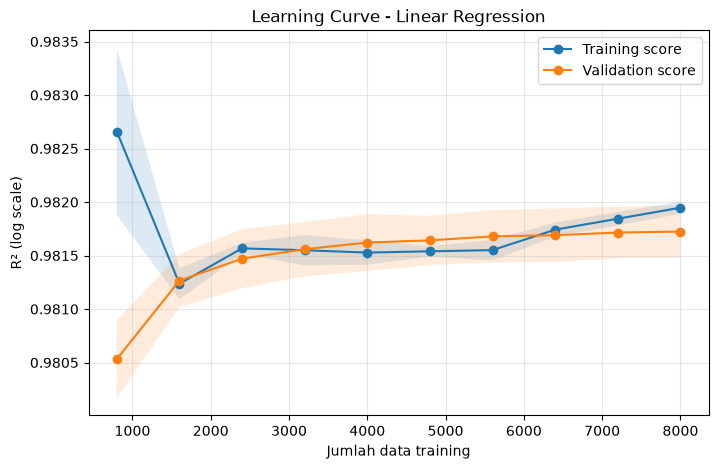

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, KFold

# pipe, X, y dari kode training sebelumnya
cv = KFold(n_splits=5, shuffle=True, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    pipe, X, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring="r2",
    n_jobs=-1,
)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", label="Training score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
plt.plot(train_sizes, val_mean, "o-", label="Validation score")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
plt.xlabel("Jumlah data training")
plt.ylabel("R² (log scale)")
plt.title("Learning Curve - Linear Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()